# Assignment 3 – Auto-encoders and Variational Auto-encoders
## Generating Minecraft item textures with an AE and a VAE

**Course:** ZM002 Artificial Intelligence – Zuyd University of Applied Sciences
**Student:** Caio Alcantara

This notebook contains the three deliverables of the assignment in one place:

| Deliverable | Sections |
|---|---|
| **Research report** – literature review on AE and VAE, which model should perform well on which dimension and why | 1, 2, 7 |
| **Realisation** – training of the AE and the VAE, latent space arithmetic, explained with in-code comments | 3, 4, 5 |
| **Evaluation report** – qualitative and quantitative comparison of reconstruction, generation and compression | 6 |

## 1. Introduction

### 1.1 The problem

An **auto-encoder** is a neural network that learns to compress its input into a short vector, the
**latent vector**, and to rebuild the input from that vector. It consists of two parts: the **encoder**
turns the input into the latent vector, and the **decoder** turns the latent vector back into the input.
Because the latent vector is much smaller than the input, the network has to learn which information is
important. Two variants are studied in this assignment:

- The **auto-encoder (AE)** only learns to rebuild its input as accurately as possible.
- The **variational auto-encoder (VAE)** learns the same, but is also forced to organise its latent
  space in a fixed way, so that new data can be generated from it (section 2).

Both models are trained on a dataset of **Minecraft item textures** and compared on two dimensions:

1. **Reconstruction quality**: how accurately does a model reproduce a texture after encoding and
   decoding it?
2. **Latent space structure**: do vector operations in the latent space lead to meaningful new
   textures? This is tested with **latent space arithmetic**. For example, the latent vector of an iron
   chestplate, minus the average latent vector of all iron items, plus the average latent vector of all
   diamond items, should decode to a texture that looks like a diamond chestplate:

$$z_{\text{iron chestplate}} - \bar{z}_{\text{iron}} + \bar{z}_{\text{diamond}} \approx z_{\text{diamond chestplate}}$$

### 1.2 The dataset

The dataset contains **719 item textures** from Minecraft: tools, armour, food, blocks and other items.
Every texture is a PNG image of only **16 × 16 pixels** with a transparent background. Many items exist
in several materials; the sword and the pickaxe, for example, exist in wood, stone, iron, gold, diamond
and netherite. This makes the dataset suitable for latent space arithmetic: the same shape can be
"moved" from one material to another, and the result can be compared with the real texture.

The small size of the images and of the dataset has two consequences:

- A texture has only 16 × 16 × 3 = 768 values (after removing the transparency, section 3.1), so small
  networks are enough and both models can be trained in a few minutes on a laptop CPU. This also makes it
  possible to train many models with different latent sizes (section 6.2).
- With only 719 examples, a model can easily memorise the training textures. Reconstruction quality is
  therefore also measured on textures the model did not see during training (section 3.3).

### 1.3 Research questions

This notebook answers the following questions:

| # | Question | Section |
|---|---|---|
| 1 | Which model reconstructs the textures more accurately, also textures it has not seen during training? | 6.1 |
| 2 | How much compression does each model allow: how small can the latent vector be before reconstruction fails? | 6.2 |
| 3 | Which model has a latent space in which arithmetic and random sampling produce meaningful new textures? | 5, 6.3, 6.4 |
| 4 | How can the differences be explained by the literature, in particular by the isotropy or anisotropy of the latent space? | 2, 7 |

Section 2 describes what the literature expects for both dimensions. To keep the comparison fair, the
AE and the VAE use the same small network; the only difference is the variational part of the VAE
(section 4). Differences in the results can therefore be attributed to that part, and not to a
different architecture.

## 2. Theoretical background

This section summarises the literature on AEs and VAEs and ends with the expected outcome for both
dimensions of the comparison (section 2.5). The main sources are the tutorial on VAEs by Doersch (2016)
and the β-VAE paper by Higgins et al. (2017), which studies the trade-off between reconstruction quality
and latent space structure.

### 2.1 Auto-encoders

An AE consists of two networks. The **encoder** maps an input $x$ (here a texture of 768 values) to a
latent vector $z$ with far fewer dimensions; the **decoder** maps $z$ back to a reconstruction
$\hat{x}$. Both are trained together to minimise the **reconstruction error**, here the sum of squared
errors over all values of the texture:

$$\mathcal{L}_{AE} = \sum_{i} (x_i - \hat{x}_i)^2$$

The small latent vector is a **bottleneck**: it forces the network to keep only the most important
information of the input. The smaller the latent vector, the stronger the compression and the more
details are lost.

For this assignment, the important point is what the loss does *not* say: it only rewards a good
reconstruction, and says nothing about *where* in the latent space a texture should be placed. The encoder
may put the textures anywhere, as long as the decoder can rebuild them. The latent space of an AE therefore
has no fixed shape, and points between or outside the encoded textures were never seen by the decoder.

### 2.2 Variational auto-encoders

The VAE (Kingma & Welling, 2014) is a **generative model**: new data is generated by drawing a random
latent vector from a standard normal distribution $\mathcal{N}(0, I)$, the **prior**, and decoding it
(Doersch, 2016). To make this possible, the encoder does not output one point per texture, but a small
region: a mean $\mu$ and a standard deviation $\sigma$ for every latent dimension. During training, the
latent vector is a random point from this region, and the decoder has to reconstruct the texture from it.

The loss has two terms:

$$\mathcal{L}_{VAE} = \text{reconstruction error} + \text{KL term}$$

The reconstruction error is the same as in the AE. The **KL term** (Kullback-Leibler divergence) measures
how much the region of a texture differs from the prior $\mathcal{N}(0, I)$. It has two effects on the
latent space:

- It pulls every $\mu$ towards the origin and every $\sigma$ towards 1. The latent vectors of all textures
  are therefore placed in the same region around the origin, in the shape of $\mathcal{N}(0, I)$.
- Because $\sigma$ cannot become 0, the decoder receives a slightly different latent vector for the same
  texture in every epoch. Nearby points must therefore decode to similar textures, which makes the latent
  space **continuous**, without empty regions between the textures.

The price is the reconstruction quality. The noise limits how much information about a single texture can
pass through the latent vector, and since nearby points decode to similar outputs, the decoder learns to
output something like the average of the textures in that region. Reconstructions of a VAE are therefore
typically **blurrier** than those of an AE.

### 2.3 Latent space structure: anisotropy and isotropy

A set of vectors is **isotropic** when it looks the same in every direction: every dimension has the same
spread and the dimensions are not correlated (the covariance matrix is proportional to the identity
matrix). The vectors form a round cloud. A set is **anisotropic** when the spread differs per direction:
a few directions contain almost all the variation, or the vectors occupy only a narrow part of the space.
Ethayarajh (2019) found such anisotropy in the word representations of language models such as BERT and
GPT-2: the vectors lie in a narrow cone, so that even two unrelated words have a high cosine similarity.
When all vectors share such a large common part, differences between them become small, and distances
and directions say little about meaning.

For the two models this leads to the following expectation:

- **VAE.** The prior $\mathcal{N}(0, I)$ is isotropic by definition, and the KL term pulls the latent
  vectors towards it. The latent space is therefore expected to be roughly isotropic: centred at the
  origin, with a similar spread in every dimension.
- **AE.** Nothing in the loss controls the shape of the latent space (section 2.1). The dimensions can have
  very different scales, can be correlated, and the textures can form clusters with empty space between
  them: the latent space is expected to be anisotropic.

This matters for two of the experiments:

1. **Sampling new textures.** For the VAE, a new texture is generated by decoding a random vector from
   $\mathcal{N}(0, I)$. For the AE it is not known which region of the latent space contains valid
   textures; a random vector will probably fall into an empty region, and the decoder output is meaningless.
2. **Latent space arithmetic** (section 2.4). The result of the arithmetic is a new point that is not the
   encoding of any texture. In the continuous latent space of the VAE it is likely to decode into a
   meaningful texture; in the latent space of the AE it may land in a region the decoder has never seen.

### 2.4 Latent space arithmetic

Vector arithmetic on learned representations is best known from word embeddings, where
$\text{vec}(\textit{king}) - \text{vec}(\textit{man}) + \text{vec}(\textit{woman})$ lies close to
$\text{vec}(\textit{queen})$ (Mikolov et al., 2013). The idea is that a property (here: the material of an
item) corresponds to a **direction** in the latent space, so that changing the property means adding a
vector.

In this assignment, the vector of a material is the **average** of the latent vectors of all items of that
material, for example for iron:

$$\bar{z}_{\text{iron}} = \frac{1}{|I|} \sum_{x \in I} z(x)$$

where $I$ is the set of all iron items. Because these items have many different shapes (sword, helmet,
ingot, ...), averaging cancels out the shape and keeps what they have in common: the material, i.e. mostly
the colours. A texture is moved from one material to another by removing the old material and adding the
new one:

$$z_{\text{new}} = z(\text{iron chestplate}) - \bar{z}_{\text{iron}} + \bar{z}_{\text{diamond}}$$

$z_{\text{new}}$ is decoded and compared with the real diamond chestplate. For the VAE the mean $\mu(x)$
is used as latent vector (without sampling), so that the result is the same every time.

This only works if (a) the material corresponds to roughly the same direction for all items, and (b) the
resulting point lies in a region of the latent space that the decoder can decode. Condition (b) is where the
structure of section 2.3 comes in.

### 2.5 Expected results: which model for which dimension?

Higgins et al. (2017) add a weight $\beta$ to the KL term of the VAE:

$$\mathcal{L}_{\beta\text{-VAE}} = \text{reconstruction error} + \beta \cdot \text{KL term}$$

With $\beta = 1$ this is the normal VAE. With $\beta > 1$ the latent space is pushed harder towards the
prior: it becomes more structured (each dimension tends to capture one property of the data), but the
reconstructions get worse. Higgins et al. describe this as a **trade-off** between reconstruction quality
and the structure of the latent space. Without the KL term ($\beta = 0$), only the reconstruction error is
left, as in the AE. The AE and the VAE can therefore be seen as two points on the same scale. This notebook
uses the normal VAE ($\beta = 1$) to keep it simple.

Based on sections 2.1 to 2.4, the expected results are:

| Dimension | AE | VAE | Why |
|---|---|---|---|
| **Reconstruction quality** | Better: sharper, lower error | Worse: blurrier | The AE uses all of its latent capacity for reconstruction; the noise and the KL term of the VAE limit the information per texture. |
| **Compression** | Error decreases as the latent vector grows | Higher error at every size; may stop improving for large latent vectors | The KL term makes it costly for the VAE to use extra dimensions, so some dimensions may stay unused. |
| **Latent space arithmetic** | Less reliable | More reliable | The VAE latent space is continuous and isotropic; the AE latent space can have empty regions. |
| **Generating new textures** | Poor | Recognisable, but blurry | Only the VAE has a known distribution ($\mathcal{N}(0, I)$) to sample from. |

### 2.6 Evaluation metrics

Section 6 measures the dimensions of section 2.5 as follows:

| What | Metric | Section |
|---|---|---|
| **Reconstruction quality** | Mean squared error (MSE) per pixel value on the test set (values between 0 and 1, lower is better), and the **PSNR** $= 10 \cdot \log_{10}(1 / \text{MSE})$ in dB (higher is better). Plus a visual comparison of original and reconstructions. | 6.1 |
| **Compression** | Both models are trained with latent sizes 2, 4, 8, 16, 32 and 64 and the test MSE is plotted against the latent size. Reconstruction has *failed* when the shape or the colours of the item can no longer be recognised. | 6.2 |
| **Generating new textures** | Visual: decode random vectors from $\mathcal{N}(0, I)$ and interpolate between two items. | 6.3 |
| **Latent space arithmetic** | MSE between the result of the arithmetic and the real target texture, compared with the MSE between the source texture and the target (e.g. iron chestplate vs. diamond chestplate). If the arithmetic works, the result is closer to the target than the source is. Averaged over all available item pairs. | 6.4 |
| **Isotropy** | The eigenvalues of the covariance matrix of all latent vectors: for an isotropic space they are all similar, for an anisotropic space a few are much larger than the rest. In addition, the average cosine similarity between random pairs of latent vectors, as in Ethayarajh (2019): close to 0 for an isotropic space around the origin. | 6.4 |

## 3. Setup and the dataset

The notebook uses **Keras** (with the TensorFlow backend) for the networks, **NumPy** for the data,
**Pillow** to read the PNG files and **Matplotlib** for the plots.

In [1]:
import pathlib
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
import keras
from keras import layers, ops

# Fix all random seeds so that the results in this notebook can be reproduced.
SEED = 42
keras.utils.set_random_seed(SEED)   # sets the seeds of Python, NumPy and the backend

DATA_DIR = pathlib.Path('minecraft-items')   # the 719 PNG files

print('Keras', keras.__version__, '| backend:', keras.backend.backend())

Keras 3.15.1 | backend: tensorflow


### 3.1 Loading the textures

Every PNG file has four channels: red, green, blue and **alpha** (transparency). The networks work with
normal RGB images, so the alpha channel is removed by drawing the texture on a **black background**, as in
the figure of the assignment: every colour value is multiplied by its alpha value, so transparent pixels
(alpha = 0) become black and opaque pixels (alpha = 1) keep their colour. A few files are stored with a
colour palette instead of RGBA; `convert('RGBA')` turns them into the same format.

The pixel values are divided by 255, so that all values are between 0 and 1. This matches the **sigmoid**
output layer of the decoders (section 4), which also produces values between 0 and 1.

In [2]:
def load_texture(path):
    # Read a PNG file and return it as a (16, 16, 3) array with values between 0 and 1.
    rgba = np.asarray(Image.open(path).convert('RGBA'), dtype='float32') / 255
    rgb, alpha = rgba[..., :3], rgba[..., 3:]
    return rgb * alpha   # transparent pixels (alpha = 0) become black


# All textures, sorted by name so that the order (and thus the split below) is always the same.
paths = sorted(DATA_DIR.glob('*.png'))
names = np.array([p.stem for p in paths])            # file name without '.png', e.g. 'iron_chestplate'
images = np.stack([load_texture(p) for p in paths])  # shape (number of textures, 16, 16, 3)

print('images:', images.shape, '| values between', images.min(), 'and', images.max())
print(f'black pixels: {np.mean(images.max(axis=-1) == 0):.0%}')

images: (719, 16, 16, 3) | values between 0.0 and 1.0
black pixels: 58%


**Observations.** All 719 textures are loaded as 16 × 16 × 3 arrays with values between 0 and 1. On average
**58%** of the pixels are black background: the item only fills the middle of the texture. A model that
outputs a black image therefore already has more than half of the pixels right, so the reconstruction error
mainly depends on how well the item itself is reproduced.

### 3.2 Exploring the data

`show_textures` plots a list of textures in a grid. It is used throughout the notebook, also for the
reconstructions and the results of the latent space arithmetic. `interpolation='nearest'` keeps the
16 × 16 pixels sharp instead of smoothing them.

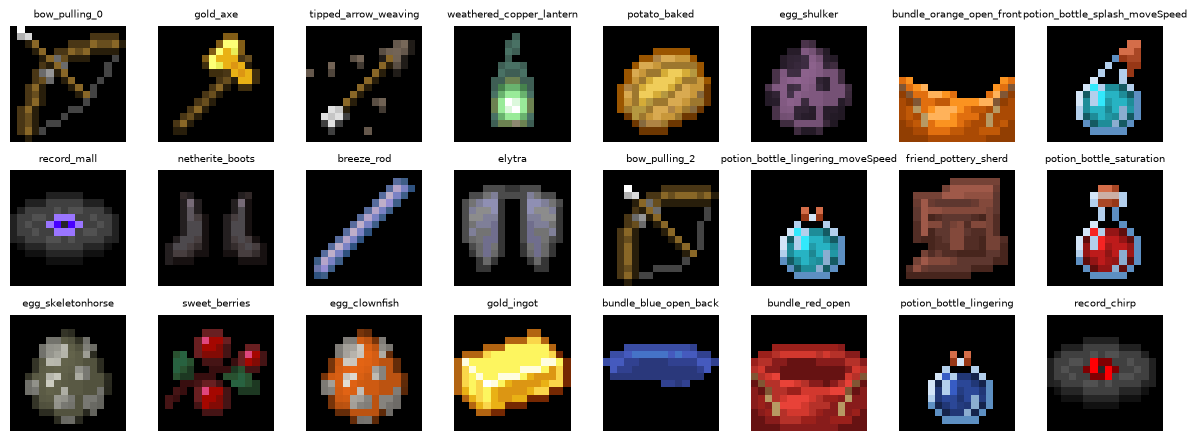

In [3]:
def show_textures(textures, titles=None, ncols=8, size=1.5):
    # Plot the textures in a grid with ncols columns, with an optional title above every texture.
    nrows = int(np.ceil(len(textures) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < len(textures):
            ax.imshow(textures[i], interpolation='nearest')
            if titles is not None:
                ax.set_title(titles[i], fontsize=7)
    plt.tight_layout()
    plt.show()


# 24 random textures
sample = np.random.default_rng(SEED).choice(len(images), size=24, replace=False)
show_textures(images[sample], names[sample])

**Observations.** The dataset is very diverse: tools, food, potions, discs, eggs, bundles, ... Some families
are large and consist of almost the same shape in different colours: there are 87 potions, 67 bundles and
64 spawn eggs, together about 30% of the dataset. For these families the colour is the only difference, the
same kind of variation as the material in the latent space arithmetic. Several items also exist in a few
animation frames (e.g. `bow_pulling_0` and `bow_pulling_2`), which are almost identical.

**Material groups.** For the latent space arithmetic (section 5), the items of every material are needed.
The material is the first word of the file name: `iron_sword` and `iron_ingot` are iron items, and the item
`diamond` (the gem itself) is a diamond item. Names in which the material is not the first word
(`raw_iron`, `door_iron`) are not counted, so that the groups contain mainly tools, armour and ingots.

In [4]:
MATERIALS = ['wood', 'stone', 'leather', 'chainmail', 'copper', 'iron', 'gold', 'diamond', 'netherite']


def items_of(material):
    # Indices of all textures whose name starts with the material, e.g. 'iron_sword' or 'iron'.
    return np.array([i for i, name in enumerate(names) if name.split('_')[0] == material])


for material in MATERIALS:
    print(f'{material:10s} {len(items_of(material)):3d} items')

wood         5 items
stone        5 items
leather      2 items
chainmail    4 items
copper      15 items
iron        12 items
gold        12 items
diamond     11 items
netherite   13 items


The iron and the diamond items, which are used for the example of the assignment
(iron chestplate → diamond chestplate):

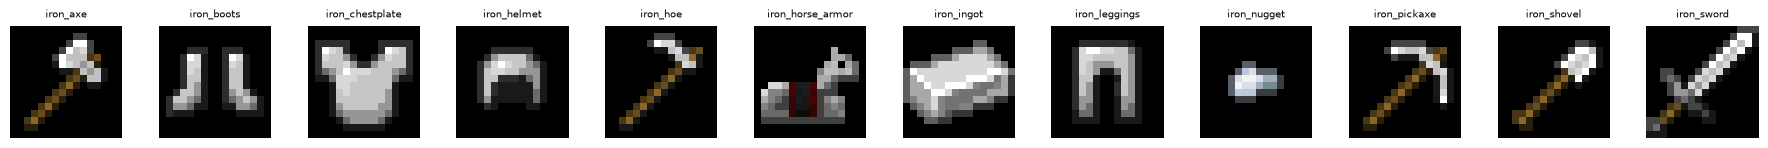

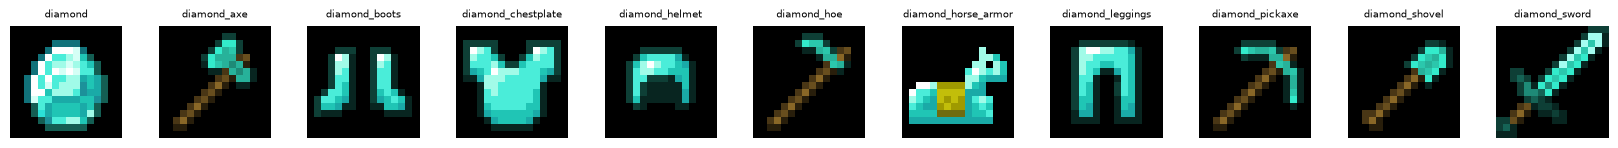

In [5]:
for material in ['iron', 'diamond']:
    indices = items_of(material)
    show_textures(images[indices], names[indices], ncols=len(indices))

**Observations.** Iron (12 items), gold (12), diamond (11), netherite (13) and copper (15) have the largest
groups, with mostly the same items: the five tools (axe, hoe, pickaxe, shovel, sword), the four armour parts
and the horse armour. The iron and diamond items have exactly the same shapes and differ mainly in colour
(light grey versus turquoise), which is what the arithmetic of section 5 has to change. Two details matter for
the material averages:

- The groups are not identical: iron has an ingot and a nugget, diamond has the gem itself instead.
- The tools have a brown wooden handle in every material. The handle is therefore part of both the iron and
  the diamond average, and should cancel out in $-\bar{z}_{\text{iron}} + \bar{z}_{\text{diamond}}$.

### 3.3 Train / test split

The textures are shuffled once and split randomly: **90%** for training and **10%** for testing. The test
set is only used to measure how well the models reconstruct textures they have never seen (section 6.1); it
is not used to choose any setting. There is no separate validation set, because the models are trained for
a fixed number of epochs and no settings are tuned (section 4).

The latent space arithmetic (section 5) uses all items of a material, in both sets.

In [6]:
# Shuffle the indices once and put the first 10% in the test set, the rest in the training set.
order = np.random.default_rng(SEED).permutation(len(images))
n_test = len(images) // 10
test_idx, train_idx = order[:n_test], order[n_test:]
x_train, x_test = images[train_idx], images[test_idx]

print('train:', x_train.shape, '| test:', x_test.shape)

train: (648, 16, 16, 3) | test: (71, 16, 16, 3)


## 4. Implementation

The implementation follows the Keras tutorial *Variational AutoEncoder* (Chollet, 2020, https://keras.io/examples/generative/vae/), which trains a
VAE on the MNIST digits. The following changes were made for this assignment:

| Tutorial | This notebook | Why |
|---|---|---|
| Input of 28 × 28 × 1 (grey digits) | Input of 16 × 16 × 3 (colour textures) | Size of the Minecraft textures. |
| Binary cross-entropy as reconstruction error | Sum of squared errors | As chosen in section 2.1, the same error for the AE and the VAE. |
| Hidden dense layer of 16 units before the latent vector | Removed | With 16 units, latent vectors larger than 16 (section 6.2) would make no sense. |
| Only a VAE | Also an AE with the same encoder and decoder | The comparison of this assignment (section 1.3). |
| Only training | Also a `test_step` | So that the loss on the test set can be shown during training. |

Both models use the same settings: a latent vector of **16** values, the **Adam** optimiser with the
default learning rate, batches of 32 textures and a fixed number of **100 epochs**. Training both models
takes less than a minute on a laptop CPU.

In [7]:
LATENT_DIM = 16   # size of the latent vector (other sizes are compared in section 6.2)
EPOCHS = 100
BATCH_SIZE = 32


def reconstruction_error(x, x_hat):
    # Sum of squared errors over all 16 x 16 x 3 values, one number per texture (section 2.1).
    return ops.sum(ops.square(x - x_hat), axis=(1, 2, 3))

**Encoder and decoder.** Both models share the same layers, taken from the tutorial:

- The **encoder** has two convolution layers with 3 × 3 filters and a stride of 2, which halve the image in
  every step (16 × 16 → 8 × 8 → 4 × 4) while the number of filters grows (32, then 64). The result is
  flattened into 4 × 4 × 64 = 1024 values. The last layer, which produces the latent vector, differs between
  the AE (section 4.1) and the VAE (section 4.2).
- The **decoder** is the mirror image: a dense layer turns the latent vector back into 4 × 4 × 64 values, and
  two *transposed* convolutions double the image in every step (4 × 4 → 8 × 8 → 16 × 16). A last transposed
  convolution with a **sigmoid** gives the three colour channels, with values between 0 and 1.

In [8]:
def build_encoder_body(inputs):
    # Convolutional part of both encoders: (16, 16, 3) -> 1024 values.
    x = layers.Conv2D(32, 3, strides=2, padding='same', activation='relu')(inputs)   # -> (8, 8, 32)
    x = layers.Conv2D(64, 3, strides=2, padding='same', activation='relu')(x)        # -> (4, 4, 64)
    return layers.Flatten()(x)                                                       # -> 1024


def build_decoder(latent_dim):
    # Mirror image of the encoder: latent vector -> (16, 16, 3) texture with values between 0 and 1.
    latent_inputs = keras.Input(shape=(latent_dim,))
    x = layers.Dense(4 * 4 * 64, activation='relu')(latent_inputs)
    x = layers.Reshape((4, 4, 64))(x)
    x = layers.Conv2DTranspose(64, 3, strides=2, padding='same', activation='relu')(x)   # -> (8, 8, 64)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding='same', activation='relu')(x)   # -> (16, 16, 32)
    outputs = layers.Conv2DTranspose(3, 3, padding='same', activation='sigmoid')(x)       # -> (16, 16, 3)
    return keras.Model(latent_inputs, outputs, name='decoder')

### 4.1 Auto-encoder

In the AE, a dense layer turns the 1024 values of the encoder into the latent vector $z$. The `AE` model
connects the encoder and the decoder; it is trained with the reconstruction error as loss and the textures
as both input and target. Encoder and decoder are kept as separate models, so that they can also be used
on their own: the encoder for the latent space arithmetic (section 5), the decoder to decode new latent
vectors.

In [9]:
class AE(keras.Model):
    # Auto-encoder: texture -> encoder -> latent vector -> decoder -> reconstruction.
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def call(self, x):
        return self.decoder(self.encoder(x))


def build_ae(latent_dim=LATENT_DIM, seed=SEED):
    keras.utils.set_random_seed(seed)   # same seed -> same initial weights
    inputs = keras.Input(shape=(16, 16, 3))
    z = layers.Dense(latent_dim, name='z')(build_encoder_body(inputs))
    ae = AE(keras.Model(inputs, z, name='encoder'), build_decoder(latent_dim))
    ae.compile(optimizer=keras.optimizers.Adam(), loss=reconstruction_error)
    return ae


ae = build_ae()
ae.encoder.summary()
ae.decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 16, 16, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 8, 8, 32)       │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ z (Dense)                       │ (None, 16)             │        16,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,792 (139.81 KB)

 Trainable params: 35,792 (139.81 KB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 64)       │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 16, 16, 3)      │           867 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73,667 (287.76 KB)

 Trainable params: 73,667 (287.76 KB)

 Non-trainable params: 0 (0.00 B)

### 4.2 Variational auto-encoder

The VAE uses the same encoder body and the same decoder, with three differences, all taken from the tutorial:

1. **Two outputs instead of one.** The encoder has two dense layers: one for the mean $\mu$ and one for
   $\log \sigma^2$, the logarithm of the variance. The network predicts $\log \sigma^2$ instead of $\sigma$
   because a dense layer can output any number, while $\sigma$ must be positive; $\sigma$ is computed from
   it as $e^{\log \sigma^2 / 2}$.
2. **The `Sampling` layer** draws the latent vector $z$ from the region of the texture (section 2.2):
   $z = \mu + \sigma \cdot \varepsilon$, with $\varepsilon$ random from $\mathcal{N}(0, I)$.
3. **The loss.** Keras cannot compute the VAE loss from the input and the output alone, because the KL term
   needs $\mu$ and $\log \sigma^2$. The `VAE` model therefore computes both terms itself in
   `train_step`: the reconstruction error and the KL term, with the formula of Kingma & Welling (2014).
   `test_step` computes the same losses on the test set, without updating the weights.

In [10]:
class Sampling(layers.Layer):
    # Draws z = mu + sigma * epsilon with epsilon from N(0, I): the reparameterisation trick (section 2.2).
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(SEED)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = keras.random.normal(ops.shape(z_mean), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon   # sigma = exp(log(sigma^2) / 2)


class VAE(keras.Model):
    # Variational auto-encoder with its own training step, because the loss also needs mu and log(sigma^2).
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        # Averages of the losses over an epoch, shown in the training history.
        self.loss_tracker = keras.metrics.Mean(name='loss')
        self.reconstruction_tracker = keras.metrics.Mean(name='reconstruction')
        self.kl_tracker = keras.metrics.Mean(name='kl')

    @property
    def metrics(self):
        # Listed here so that Keras resets the averages at the start of every epoch.
        return [self.loss_tracker, self.reconstruction_tracker, self.kl_tracker]

    def vae_losses(self, x):
        # Both terms of the VAE loss (section 2.2), averaged over the textures of the batch.
        z_mean, z_log_var, z = self.encoder(x)
        reconstruction = self.decoder(z)
        reconstruction_loss = ops.mean(reconstruction_error(x, reconstruction))
        # KL divergence between N(mu, sigma^2) and N(0, I), summed over the latent dimensions.
        kl = -0.5 * (1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var))
        kl_loss = ops.mean(ops.sum(kl, axis=1))
        return reconstruction_loss, kl_loss

    def update_metrics(self, reconstruction_loss, kl_loss):
        self.loss_tracker.update_state(reconstruction_loss + kl_loss)
        self.reconstruction_tracker.update_state(reconstruction_loss)
        self.kl_tracker.update_state(kl_loss)
        return {m.name: m.result() for m in self.metrics}

    def train_step(self, data):
        x, _ = data   # the target is the input itself
        with tf.GradientTape() as tape:   # records the computations, to calculate the gradients
            reconstruction_loss, kl_loss = self.vae_losses(x)
            total_loss = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        return self.update_metrics(reconstruction_loss, kl_loss)

    def test_step(self, data):
        x, _ = data
        return self.update_metrics(*self.vae_losses(x))   # same losses, but no weight update


def build_vae(latent_dim=LATENT_DIM, seed=SEED):
    keras.utils.set_random_seed(seed)   # same seed -> same initial weights
    inputs = keras.Input(shape=(16, 16, 3))
    h = build_encoder_body(inputs)
    z_mean = layers.Dense(latent_dim, name='z_mean')(h)
    z_log_var = layers.Dense(latent_dim, name='z_log_var')(h)
    z = Sampling()([z_mean, z_log_var])
    vae = VAE(keras.Model(inputs, [z_mean, z_log_var, z], name='encoder'), build_decoder(latent_dim))
    vae.compile(optimizer=keras.optimizers.Adam())
    return vae


vae = build_vae()
vae.encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 16, 16, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 8, 32)  │        896 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 4, 4, 64)  │     18,496 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 1024)      │          0 │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │     16,400 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │     16,400 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 52,192 (203.88 KB)

 Trainable params: 52,192 (203.88 KB)

 Non-trainable params: 0 (0.00 B)

The VAE encoder has one extra dense layer ($\log \sigma^2$), so 16 400 parameters more than the AE encoder.
The decoders are identical.

### 4.3 Training

Both models are trained the same way: 100 epochs, with the training textures as input and as target. The
loss on the test set is computed after every epoch, but only to show it in the plots below; it is not used to
choose anything.

AE: trained in 13 s
VAE: trained in 13 s
AE: reconstruction error train 4.4, test 7.3
VAE: reconstruction error train 12.2, test 14.4


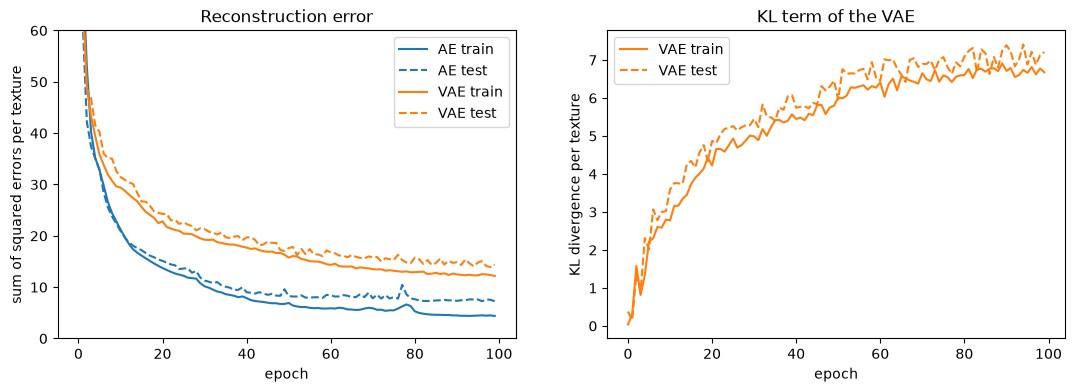

VAE: KL term train 6.7, test 7.2


In [11]:
def train(model):
    # Train for a fixed number of epochs; the textures are both the input and the target.
    start = time.time()
    history = model.fit(x_train, x_train, validation_data=(x_test, x_test),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    print(f'{model.__class__.__name__}: trained in {time.time() - start:.0f} s')
    return history.history


ae_history = train(ae)
vae_history = train(vae)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
# For the AE the loss is the reconstruction error; for the VAE it is stored as 'reconstruction'.
for name, history, key, colour in [('AE', ae_history, 'loss', 'C0'), ('VAE', vae_history, 'reconstruction', 'C1')]:
    ax1.plot(history[key], color=colour, label=f'{name} train')
    ax1.plot(history['val_' + key], color=colour, linestyle='--', label=f'{name} test')
    print(f'{name}: reconstruction error train {history[key][-1]:.1f}, test {history["val_" + key][-1]:.1f}')
ax1.set(title='Reconstruction error', xlabel='epoch', ylabel='sum of squared errors per texture', ylim=(0, 60))
ax1.legend()

ax2.plot(vae_history['kl'], color='C1', label='VAE train')
ax2.plot(vae_history['val_kl'], color='C1', linestyle='--', label='VAE test')
ax2.set(title='KL term of the VAE', xlabel='epoch', ylabel='KL divergence per texture')
ax2.legend()
plt.show()
print(f'VAE: KL term train {vae_history["kl"][-1]:.1f}, test {vae_history["val_kl"][-1]:.1f}')

**Observations.** Both models train without problems and their curves are flat at the end, so 100 epochs
are enough.

- **Reconstruction error.** As expected (section 2.5), the AE reconstructs better than the VAE: after 100
  epochs its test error is **7.3** per texture, against **14.4** for the VAE, about twice as high. Divided by
  the 768 values of a texture, this is a mean squared error of about 0.010 and 0.019 per value. (The test
  error of the VAE is computed with a random $z$, as during training; section 6.1 measures it with $\mu$.)
- **Overfitting.** The test error of the AE stops improving around epoch 50, while its training error keeps
  going down (4.4 at the end): the AE starts to memorise the training textures. The VAE has a smaller gap
  between training and test (12.2 versus 14.4), because the noise of the sampling makes it harder to
  memorise single textures.
- **KL term.** At the start the KL term is almost 0: the encoder outputs about $\mathcal{N}(0, I)$ for every
  texture, so the latent vector contains no information about the texture yet. During training the VAE
  "spends" more KL to put information into the latent vector and reduce the reconstruction error, until the
  two terms are in balance at about 7. This is the trade-off of section 2.5 in practice.

## 5. Latent space arithmetic

This section applies the method of section 2.4 to the trained AE and VAE of section 4 and shows the results
visually. Section 6.4 measures how well it works.

Two small functions are used for both models:

- `encode` returns the latent vectors of textures. For the VAE this is the mean $\mu$, without sampling,
  so that the result is the same every time (section 2.4).
- `decode` turns latent vectors back into textures with the decoder.

Both call the model directly instead of using `predict`, which is meant for large datasets in batches
and is slow for a few textures at a time.

In [12]:
def encode(model, x):
    # Latent vectors of the textures x. The VAE encoder returns [mu, log(sigma^2), z]: only mu is used.
    z = model.encoder(x)
    return ops.convert_to_numpy(z[0] if isinstance(model, VAE) else z)


def decode(model, z):
    # Textures for the latent vectors z.
    return ops.convert_to_numpy(model.decoder(z))

### 5.1 Material vectors

The vector of a material is the average latent vector of all its items (section 3.2). To see what such a
vector contains, it can be decoded like any other latent vector:

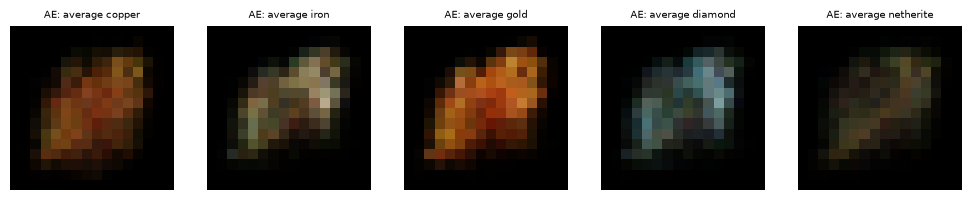

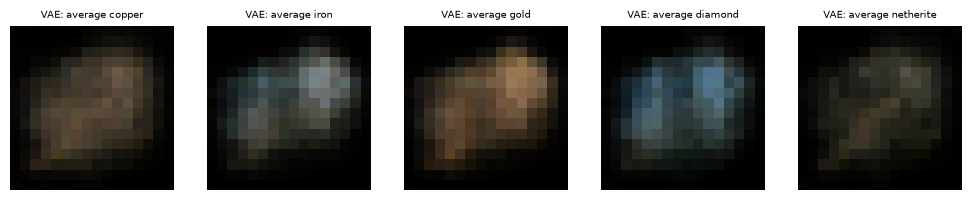

In [13]:
SHOWN_MATERIALS = ['copper', 'iron', 'gold', 'diamond', 'netherite']


def material_vector(model, material):
    # Average latent vector of all items of the material (section 2.4).
    return encode(model, images[items_of(material)]).mean(axis=0)


for name, model in [('AE', ae), ('VAE', vae)]:
    vectors = np.array([material_vector(model, m) for m in SHOWN_MATERIALS])
    show_textures(decode(model, vectors), [f'{name}: average {m}' for m in SHOWN_MATERIALS], ncols=5, size=2)

**Observations.** The decoded material vectors look like the figure of the assignment: a blurry diagonal
shape, because most items are tools that lie diagonally and the average mixes all their shapes. What remains
is the **colour** of the material: orange for copper and gold, light grey for iron, blue for diamond and dark
brown-grey for netherite. The averages of the AE have clearer colours; those of the VAE are greyer and more
alike (iron and diamond are both blue-grey), because the VAE places all textures closer to the origin, so the
averages of different materials also lie closer together.

### 5.2 Iron chestplate → diamond chestplate

The example of the assignment:
$z(\text{iron chestplate}) - \bar{z}_{\text{iron}} + \bar{z}_{\text{diamond}}$. `change_material` computes
this new latent vector and decodes it. The figure shows the same five steps as the figure in the assignment,
for both models.

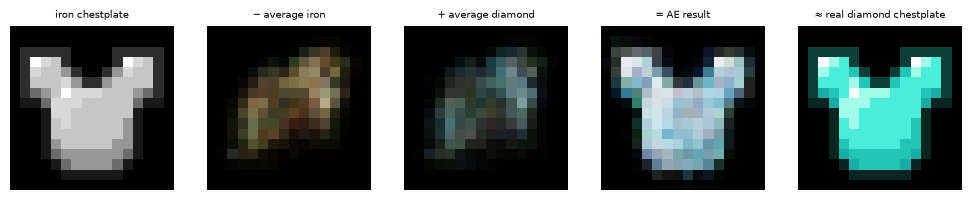

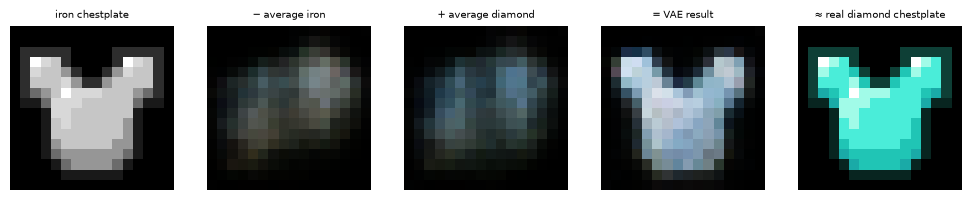

In [14]:
def change_material(model, item, old, new):
    # z(item) - average old material + average new material, decoded back into a texture.
    z = encode(model, images[names == item])[0]
    z_new = z - material_vector(model, old) + material_vector(model, new)
    return decode(model, z_new[None])[0]   # [None]: the decoder expects a batch of vectors


for name, model in [('AE', ae), ('VAE', vae)]:
    textures = [
        images[names == 'iron_chestplate'][0],
        decode(model, material_vector(model, 'iron')[None])[0],
        decode(model, material_vector(model, 'diamond')[None])[0],
        change_material(model, 'iron_chestplate', 'iron', 'diamond'),
        images[names == 'diamond_chestplate'][0],
    ]
    titles = ['iron chestplate', '− average iron', '+ average diamond', f'= {name} result', '≈ real diamond chestplate']
    show_textures(textures, titles, ncols=5, size=2)

**Observations.** Both models turn the iron chestplate into a **light blue chestplate**: the shape is kept
exactly, and the colour moves in the direction of diamond. Neither result reaches the turquoise of the real
diamond chestplate, and both are noisier than a real texture. The AE result is slightly more saturated and
contains a few white and dark pixels that do not belong there; the VAE result is smoother but greyer, as
expected from its blurrier reconstructions (section 4.3).

### 5.3 Other transformations

The same operation for other items and between other materials. Every row shows the original item, the result
of the AE, the result of the VAE and the real item in the new material.

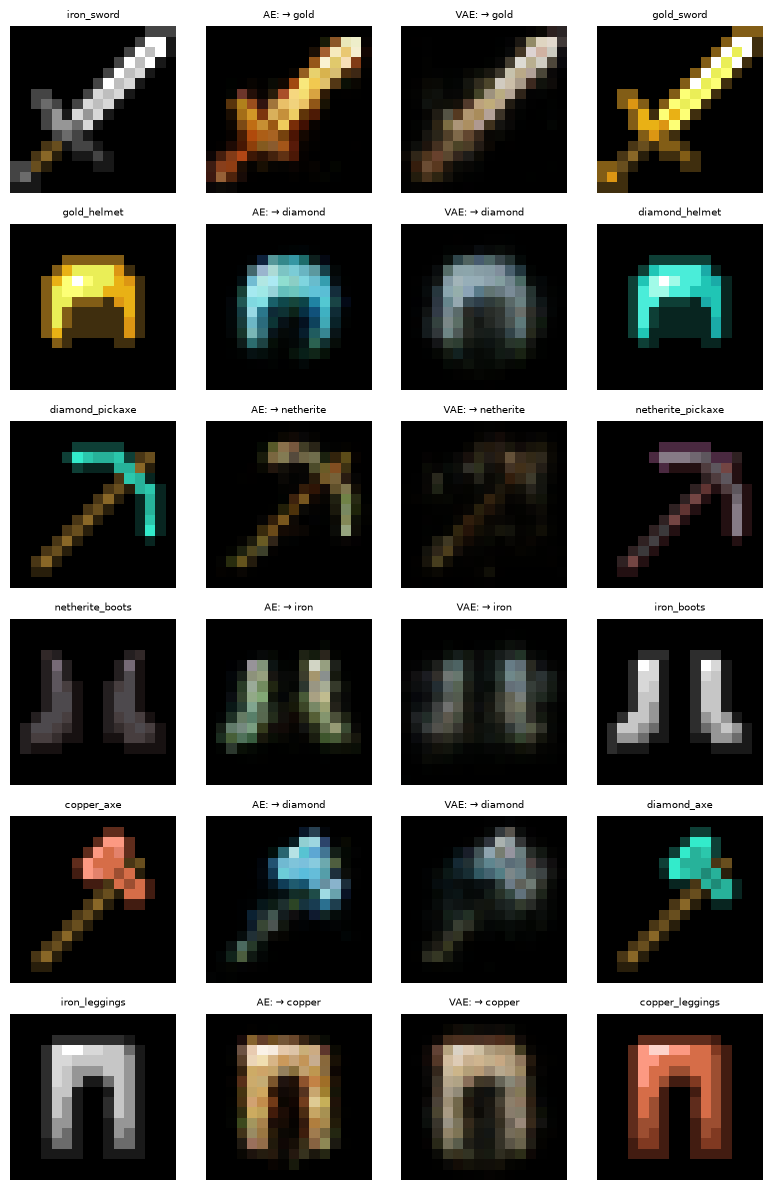

In [15]:
# (item, old material, new material); the real target is the item name with the new material.
TRANSFORMATIONS = [
    ('iron_sword', 'iron', 'gold'),
    ('gold_helmet', 'gold', 'diamond'),
    ('diamond_pickaxe', 'diamond', 'netherite'),
    ('netherite_boots', 'netherite', 'iron'),
    ('copper_axe', 'copper', 'diamond'),
    ('iron_leggings', 'iron', 'copper'),
]

textures, titles = [], []
for item, old, new in TRANSFORMATIONS:
    target = item.replace(old, new)
    textures += [images[names == item][0], change_material(ae, item, old, new),
                 change_material(vae, item, old, new), images[names == target][0]]
    titles += [item, f'AE: → {new}', f'VAE: → {new}', target]
show_textures(textures, titles, ncols=4, size=2)

**Observations.** In all six cases both models keep the **shape** of the item; only the colour changes.
How well the colour changes depends on the materials:

- **Clear colour differences work best.** Iron → gold, gold → diamond and copper → diamond give a result
  with roughly the colour of the target. Iron → copper gives a light brown instead of the copper orange.
- **Dark materials work poorly.** Diamond → netherite and netherite → iron hardly change the brightness:
  the pickaxe becomes greenish-brown instead of dark purple-grey, and the boots stay dark instead of turning
  light grey.
- **AE versus VAE.** Visually, the results of the AE are sharper and closer to the target colour than those
  of the VAE, which are greyer and more faded. This is the opposite of the expectation of section 2.5, where
  the VAE was expected to do better at arithmetic. A possible reason is that these transformations stay close
  to the real textures: the result is a known shape in a known colour, so the AE decoder never has to decode
  an "empty" region of its latent space (section 2.3). Section 6.4 checks the arithmetic quantitatively;
  section 6.3 tests both decoders on random points that are further away from the training textures.

## 6. Evaluation

This section measures the dimensions of section 2.5 with the metrics of section 2.6:

1. **Reconstruction quality** of the models of section 4 (6.1).
2. **Compression**: the same models trained with smaller and larger latent vectors (6.2).
3. **Generating new textures** from random latent vectors and by interpolation (6.3).
4. **Latent space structure**: the latent space arithmetic of section 5 for all available item pairs, and the
   isotropy of both latent spaces (6.4).

All errors are the **mean squared error (MSE) per pixel value** (between 0 and 1), so that they do not depend
on the size of the texture. For the VAE the mean $\mu$ is used as latent vector, without sampling.

In [16]:
def mse(a, b):
    # Mean squared error per pixel value, one number per texture.
    return np.mean(np.square(a - b), axis=(1, 2, 3))


def psnr(error):
    # Peak signal-to-noise ratio in dB for pixel values between 0 and 1 (higher is better).
    return 10 * np.log10(1 / error)


def reconstruct(model, x):
    # Encode and decode the textures x.
    return decode(model, encode(model, x))

### 6.1 Reconstruction quality

The reconstruction error on the training set and on the test set, for both models:

In [17]:
for name, model in [('AE', ae), ('VAE', vae)]:
    for set_name, x in [('train', x_train), ('test', x_test)]:
        error = mse(x, reconstruct(model, x)).mean()
        print(f'{name:3s} {set_name:5s}: MSE {error:.4f} | PSNR {psnr(error):.1f} dB')

AE  train: MSE 0.0055 | PSNR 22.6 dB
AE  test : MSE 0.0095 | PSNR 20.2 dB
VAE train: MSE 0.0115 | PSNR 19.4 dB
VAE test : MSE 0.0141 | PSNR 18.5 dB


**Interpretation.** On the test set the AE has a **1.5 times lower error** than the VAE (MSE 0.0095 against
0.0141, or 20.2 dB against 18.5 dB PSNR), as expected in section 2.5. The difference between training and
test error is larger for the AE (0.0055 → 0.0095) than for the VAE (0.0115 → 0.0141): the AE has partly
memorised the training textures, as already seen in section 4.3.

Twelve textures of the test set (never seen during training), with the reconstructions of both models:

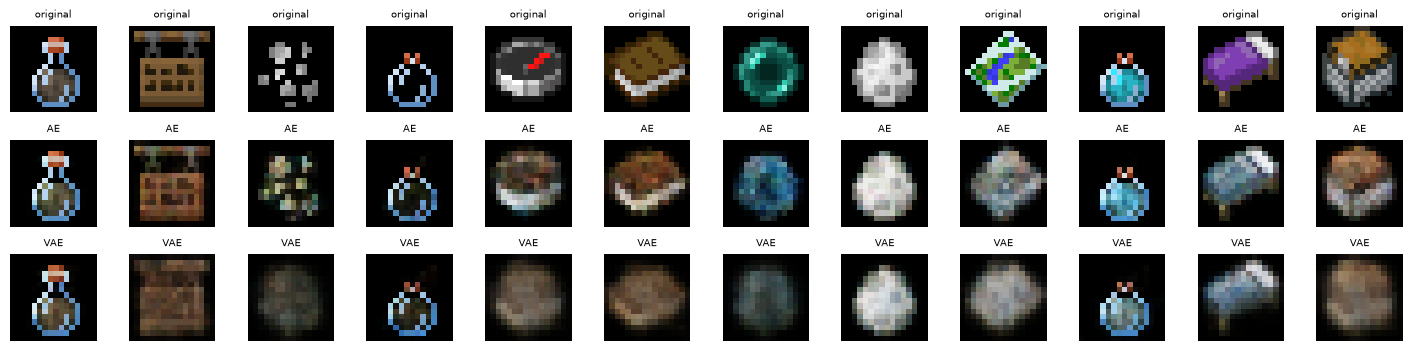

In [18]:
shown = x_test[:12]
show_textures(np.concatenate([shown, reconstruct(ae, shown), reconstruct(vae, shown)]),
              ['original'] * 12 + ['AE'] * 12 + ['VAE'] * 12, ncols=12, size=1.2)

**Interpretation.** Both models reconstruct the potions almost perfectly; there are 87 potions in the dataset,
so this shape is well learned. For the other items the difference is clear:

- The **AE** keeps the shape and the main colours of most items (the sign, the book, the egg, the minecart),
  but loses details: the red needle of the compass disappears, the colours of the map are mixed, the scattered
  spots of the third item become noisy, and the purple bed turns blue-grey.
- The **VAE** only reconstructs common shapes sharply: the potions, the egg (64 eggs in the dataset) and the
  bed (16 beds), although the bed also loses its purple colour. Less common items such as the sign, the
  compass, the book, the map and the minecart become blurry brown or grey blobs: the VAE falls back to
  something like the average texture of that region of its latent space, as described in section 2.2.

### 6.2 Compression: how small can the latent space be?

Both models are trained again with latent vectors of 2, 4, 8, 16, 32 and 64 values, with all other settings
as in section 4 (size 16 is the configuration of section 4). A texture has 768 values, so a latent vector of
2 values is a compression of 384 times, a latent vector of 64 values a compression of 12 times.

For the VAE, the number of **active dimensions** is also counted: dimensions in which $\mu$ actually differs
between textures. A dimension in which $\mu$ hardly changes, while the sampling adds noise with a standard
deviation of about 1, carries almost no information about the texture: the decoder only receives the noise of the
prior (section 2.5). A dimension is counted as active when the variance of $\mu$ over all textures is above
0.1, i.e. at least 10% of the variance of the prior. Training the 12 models takes about 3 minutes.

AE: trained in 12 s
VAE: trained in 14 s
AE: trained in 12 s
VAE: trained in 14 s
AE: trained in 13 s
VAE: trained in 14 s
AE: trained in 13 s
VAE: trained in 13 s
AE: trained in 13 s
VAE: trained in 14 s
AE: trained in 15 s
VAE: trained in 15 s
latent size compression   AE MSE  VAE MSE  VAE active dims
          2        384x   0.0270   0.0273          2 of 2
          4        192x   0.0188   0.0187          4 of 4
          8         96x   0.0126   0.0149          8 of 8
         16         48x   0.0095   0.0141         11 of 16
         32         24x   0.0088   0.0169         12 of 32
         64         12x   0.0089   0.0186         10 of 64


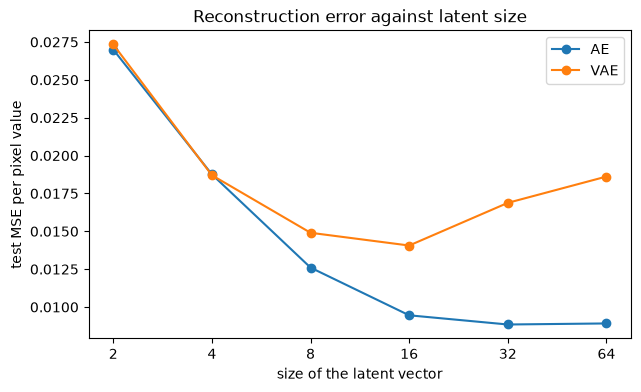

In [19]:
LATENT_SIZES = [2, 4, 8, 16, 32, 64]

compression_models = {}   # (model name, latent size) -> trained model
for size in LATENT_SIZES:
    for name, build in [('AE', build_ae), ('VAE', build_vae)]:
        model = build(size)
        train(model)
        compression_models[name, size] = model

compression_errors = {}   # (model name, latent size) -> test MSE
print(f'{"latent size":>11s} {"compression":>11s} {"AE MSE":>8s} {"VAE MSE":>8s} {"VAE active dims":>16s}')
for size in LATENT_SIZES:
    for name in ['AE', 'VAE']:
        compression_errors[name, size] = mse(x_test, reconstruct(compression_models[name, size], x_test)).mean()
    active = np.sum(encode(compression_models['VAE', size], images).var(axis=0) > 0.1)
    print(f'{size:11d} {768 / size:10.0f}x {compression_errors["AE", size]:8.4f} '
          f'{compression_errors["VAE", size]:8.4f} {active:10d} of {size}')

fig, ax = plt.subplots(figsize=(7, 4))
positions = range(len(LATENT_SIZES))   # equal distances, because every size is double the previous one
for name in ['AE', 'VAE']:
    ax.plot(positions, [compression_errors[name, size] for size in LATENT_SIZES], marker='o', label=name)
ax.set_xticks(positions, LATENT_SIZES)
ax.set(xlabel='size of the latent vector', ylabel='test MSE per pixel value',
       title='Reconstruction error against latent size')
ax.legend()
plt.show()

Four test textures, reconstructed by every model (one row per latent size, AE on the left, VAE on the right):

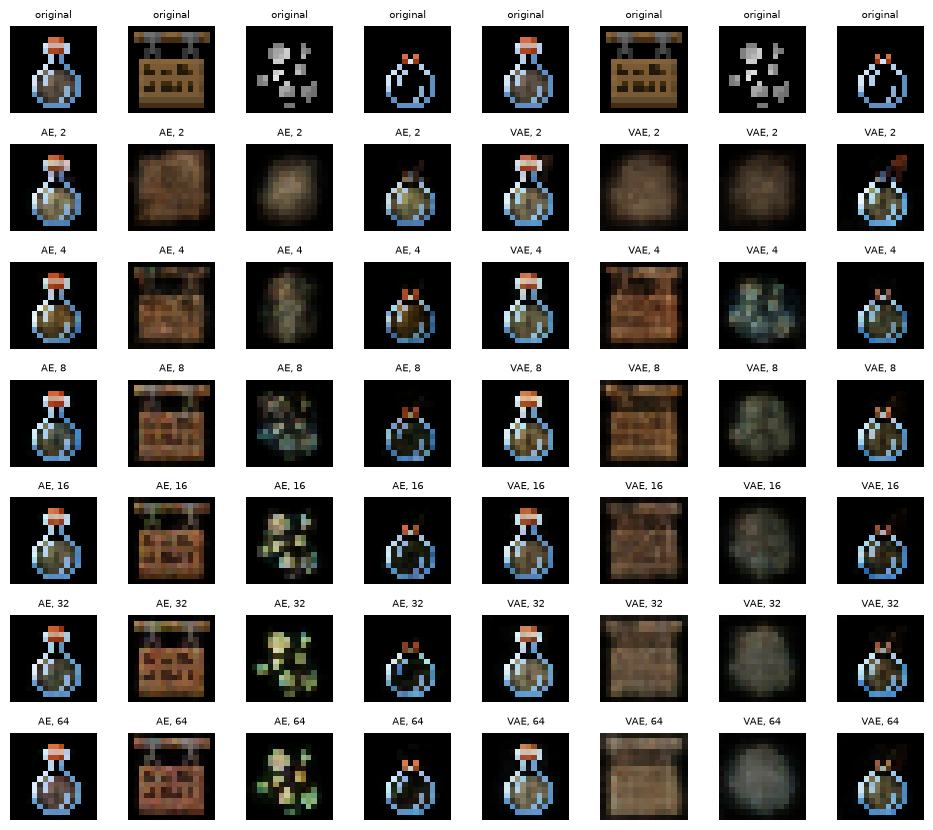

In [20]:
shown = x_test[:4]
textures, titles = list(shown) + list(shown), ['original'] * 8
for size in LATENT_SIZES:
    textures += list(reconstruct(compression_models['AE', size], shown))
    textures += list(reconstruct(compression_models['VAE', size], shown))
    titles += [f'AE, {size}'] * 4 + [f'VAE, {size}'] * 4
show_textures(textures, titles, ncols=8, size=1.2)

**Interpretation.** The reconstruction error behaves differently for the two models:

- **Strong compression (2 and 4 values)** gives the same error for both models (0.027 and 0.019). With 2 values,
  reconstruction **fails** for everything except the potion: the sign and the spotted third item become brown
  or grey blobs. With 4 values the shape of the sign comes back, but details and less common items are still lost.
  So both models need at least about **8 values** (a compression of 96 times) before most textures are
  recognisable.
- **The AE** improves up to 16 values and then stays flat (0.0088 at 32, 0.0089 at 64). From that point the
  latent size is not the limit anymore; with 648 training textures, the error on unseen textures is limited by
  how well the model generalises.
- **The VAE** is best at 16 values and gets **worse** with 32 and 64. The number of active dimensions explains
  this: whatever the size of the latent vector, the VAE only uses about **10 to 12 dimensions**. Every extra
  dimension costs KL (section 2.5), so the VAE prefers to leave it equal to the prior. These unused
  dimensions only add noise; the larger VAEs probably need more than 100 epochs to learn to ignore them fully
  (a separate check with 300 epochs, not shown here, lowered the error at 64 values from 0.0186 to 0.0131,
  still worse than the AE). For the VAE, the KL term therefore sets the compression itself: about 10 values.

### 6.3 Generating new textures

**Random latent vectors.** Sixteen random vectors from $\mathcal{N}(0, I)$, decoded by both decoders. For the
VAE this is how new data is generated (section 2.2); for the AE nothing guarantees that these vectors lie in
the region where its textures are (section 2.3). To see why, the spread of the latent vectors of all textures
is printed first.

AE  latent vectors: mean between -6.40 and  4.91, standard deviation between 3.23 and 7.27
VAE latent vectors: mean between -0.11 and  0.05, standard deviation between 0.20 and 1.07


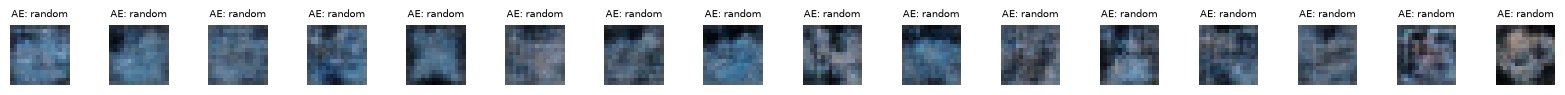

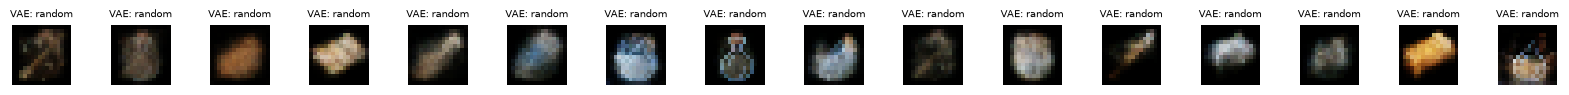

In [21]:
for name, model in [('AE', ae), ('VAE', vae)]:
    z = encode(model, images)
    print(f'{name:3s} latent vectors: mean between {z.mean(axis=0).min():5.2f} and {z.mean(axis=0).max():5.2f}, '
          f'standard deviation between {z.std(axis=0).min():.2f} and {z.std(axis=0).max():.2f}')

z_random = np.random.default_rng(SEED).normal(size=(16, LATENT_DIM)).astype('float32')
for name, model in [('AE', ae), ('VAE', vae)]:
    show_textures(decode(model, z_random), [f'{name}: random'] * 16, ncols=16, size=1)

**Interpretation.** The printed spread explains the result:

- The latent vectors of the **AE** have means between −6.4 and 4.9 and standard deviations between 3 and 7
  per dimension: they are spread over a much larger region than $\mathcal{N}(0, I)$, and not centred at the
  origin. The random vectors therefore fall into a small region near the origin where the AE has seen hardly
  any textures, and the decoder produces **blue-grey noise** without any item in it.
- The latent vectors of the **VAE** have means close to 0 and standard deviations up to about 1, so they
  match the prior, as the KL term demands. Its random vectors decode into **recognisable but blurry items**:
  a potion, ingots, tools, a bottle. This is the generative ability that section 2.2 describes.

**Interpolation.** The latent vectors of two very different items, an iron sword and an apple, are mixed in
eight steps: $z = (1 - t) \cdot z_{\text{sword}} + t \cdot z_{\text{apple}}$ with $t$ from 0 to 1. The
points in between are not the encoding of any texture.

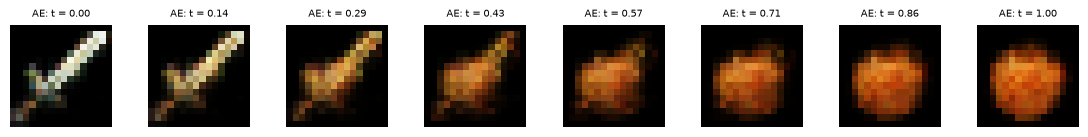

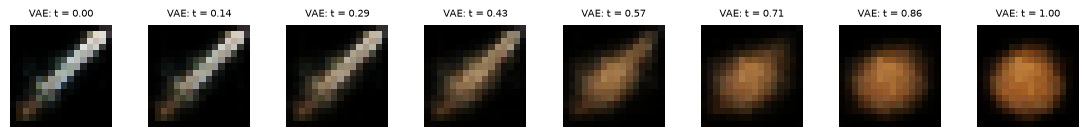

In [22]:
t = np.linspace(0, 1, 8)[:, None]   # 8 steps from 0 to 1, as a column for broadcasting
for name, model in [('AE', ae), ('VAE', vae)]:
    z_sword, z_apple = encode(model, images[(names == 'iron_sword') | (names == 'apple')][::-1])
    show_textures(decode(model, (1 - t) * z_sword + t * z_apple), [f'{name}: t = {s:.2f}' for s in t[:, 0]],
                  ncols=8, size=1.4)

**Interpretation.** The interpolation shows the continuity of the two latent spaces (section 2.2):

- **AE.** The sword first turns gold and orange, then the shape breaks up: at $t = 0.43$ and $t = 0.57$ the
  texture is a noisy mix that is neither a sword nor an apple. These points lie between the encoded textures,
  in a region the AE decoder was never trained on.
- **VAE.** Every step is a plausible, blurry shape: the sword becomes shorter and wider and changes colour
  step by step until it is the apple. Because the VAE decoder has learned that nearby points decode to
  similar textures, there are no "holes" on the way.

### 6.4 Latent space structure

**Latent space arithmetic for all item pairs.** The arithmetic of section 5 is applied to every item that
exists in two of the five large material groups (copper, iron, gold, diamond, netherite), in both
directions: for example `iron_axe` → `diamond_axe` and `diamond_axe` → `iron_axe`. For every pair three
errors are computed against the real target texture:

- **source**: the original item, without any change (doing nothing).
- **arithmetic**: the result of the arithmetic.
- **reconstruction**: the reconstruction of the target itself by the same model. This is about the best the
  decoder can do, and makes the comparison fair for the VAE, which reconstructs less sharply anyway.

In [23]:
ARITHMETIC_MATERIALS = ['copper', 'iron', 'gold', 'diamond', 'netherite']

pairs = []   # (item, old material, new material, target item)
for old in ARITHMETIC_MATERIALS:
    for new in ARITHMETIC_MATERIALS:
        for item in names[items_of(old)].tolist():
            target = new + item[len(old):]   # 'iron_axe' -> 'diamond_axe'
            if old != new and target in names:
                pairs.append((item, old, new, target))
print(len(pairs), 'pairs, e.g.', pairs[:3])

sources = np.array([images[names == item][0] for item, _, _, _ in pairs])
targets = np.array([images[names == target][0] for _, _, _, target in pairs])
print(f'\n{"":5s} {"source":>8s} {"arithmetic":>11s} {"reconstruction":>15s} {"arithmetic better than source":>30s}')
for name, model in [('AE', ae), ('VAE', vae)]:
    results = np.array([change_material(model, item, old, new) for item, old, new, _ in pairs])
    source_error, result_error = mse(sources, targets), mse(results, targets)
    reconstruction_error_ = mse(reconstruct(model, targets), targets)
    print(f'{name:5s} {source_error.mean():8.4f} {result_error.mean():11.4f} {reconstruction_error_.mean():15.4f} '
          f'{np.mean(result_error < source_error):29.0%}')

218 pairs, e.g. [('copper_axe', 'copper', 'iron', 'iron_axe'), ('copper_boots', 'copper', 'iron', 'iron_boots'), ('copper_chestplate', 'copper', 'iron', 'iron_chestplate')]

        source  arithmetic  reconstruction  arithmetic better than source
AE      0.0280      0.0136          0.0042                           90%
VAE     0.0280      0.0167          0.0105                           73%


**Interpretation.** The arithmetic works for both models: for the 218 pairs, the error to the real target
drops from 0.028 (doing nothing) to **0.0136 for the AE** and **0.0167 for the VAE**. In absolute numbers
the AE is better, and its result is closer to the target than the source in 90% of the pairs, against 73%
for the VAE. This confirms the visual impression of section 5.

The last column puts this into perspective. The AE result is **3.2 times** worse than its own reconstruction
of the target (0.0136 against 0.0042), the VAE result only **1.6 times** (0.0167 against 0.0105). The VAE
therefore loses much less by the arithmetic itself; it loses mainly because its decoder is blurrier. The AE
wins because its decoder is sharper, and because these results stay close to real items in its training set:
a known shape in a known colour. As seen in section 6.3, the AE has problems as soon as a point lies further
away from the encoded textures.

**Isotropy.** For the latent vectors of all 719 textures, two measures of section 2.6:

- The **eigenvalues of the covariance matrix**, sorted from large to small and divided by their sum: the
  share of the total variance in every direction. For an isotropic space every direction has the same share
  (1/16 = 6%); for an anisotropic space a few directions have most of it.
- The **average cosine similarity** between 1000 random pairs of latent vectors: close to 0 for an isotropic
  space around the origin, close to 1 when all vectors point in the same direction (Ethayarajh, 2019).

AE : largest direction 29% of the variance, first 3 directions 64%, average cosine similarity 0.39
VAE: largest direction 17% of the variance, first 3 directions 47%, average cosine similarity 0.01


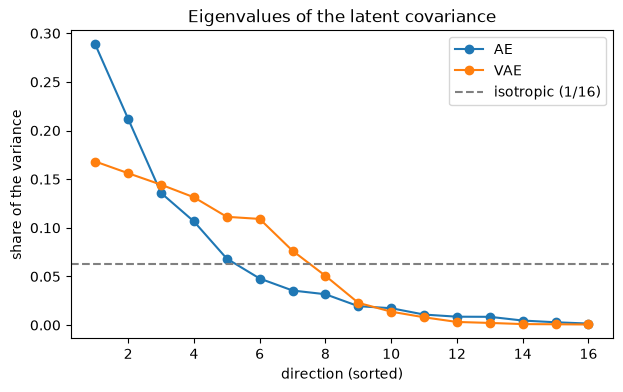

In [24]:
rng = np.random.default_rng(SEED)
first, second = rng.integers(0, len(images), size=(2, 1000))   # 1000 random pairs of textures

fig, ax = plt.subplots(figsize=(7, 4))
for name, model in [('AE', ae), ('VAE', vae)]:
    z = encode(model, images)
    eigenvalues = np.sort(np.linalg.eigvalsh(np.cov(z, rowvar=False)))[::-1]   # largest first
    share = eigenvalues / eigenvalues.sum()
    ax.plot(range(1, LATENT_DIM + 1), share, marker='o', label=name)

    cosine = np.sum(z[first] * z[second], axis=1) / (np.linalg.norm(z[first], axis=1) * np.linalg.norm(z[second], axis=1))
    print(f'{name:3s}: largest direction {share[0]:.0%} of the variance, first 3 directions {share[:3].sum():.0%}, '
          f'average cosine similarity {cosine.mean():.2f}')

ax.axhline(1 / LATENT_DIM, color='grey', linestyle='--', label='isotropic (1/16)')
ax.set(xlabel='direction (sorted)', ylabel='share of the variance', title='Eigenvalues of the latent covariance')
ax.legend()
plt.show()

**Interpretation.** The two latent spaces have a clearly different shape, as expected in section 2.3:

- The **AE** latent space is **anisotropic**. One direction contains 29% of the variance and the first three
  together 64%; the share then drops quickly. The average cosine similarity of 0.39 shows that the latent
  vectors point roughly in the same direction, because they are not centred at the origin (section 6.3). This
  is the same kind of anisotropy that Ethayarajh (2019) found in word representations.
- The **VAE** latent space is much closer to **isotropic**. About eight directions have a similar share of
  the variance (17% to 8%), and the average cosine similarity is 0.01: the vectors are spread around the origin
  in all directions. It is not perfectly isotropic, because the remaining dimensions have almost no variance:
  these are the unused dimensions of section 6.2, in which every texture is encoded as the prior.

### 6.5 Summary

| Dimension | Measure | AE | VAE | Better |
|---|---|---|---|---|
| **Reconstruction quality** | Test MSE / PSNR (6.1) | 0.0095 / 20.2 dB | 0.0141 / 18.5 dB | AE |
| | Train → test MSE (6.1) | 0.0055 → 0.0095 | 0.0115 → 0.0141 | VAE (less overfitting) |
| **Compression** | Test MSE with 2 / 4 values (6.2) | 0.0270 / 0.0188 | 0.0273 / 0.0187 | equal |
| | Best test MSE (latent size) (6.2) | 0.0088 (32) | 0.0141 (16) | AE |
| | Dimensions actually used (6.2) | all | about 10–12 | – |
| **Generating new textures** | Random vectors from $\mathcal{N}(0, I)$ (6.3) | noise | blurry, recognisable items | VAE |
| | Interpolation (6.3) | breaks up in the middle | smooth | VAE |
| **Latent space arithmetic** | Test MSE to the real target, 218 pairs (6.4) | 0.0136 | 0.0167 | AE |
| | Better than the source (6.4) | 90% | 73% | AE |
| | Arithmetic error / reconstruction error (6.4) | 3.2 × | 1.6 × | VAE |
| **Isotropy** | Largest direction / average cosine similarity (6.4) | 29% / 0.39 | 17% / 0.01 | VAE |

Most expectations of section 2.5 are confirmed: the AE reconstructs better and allows more useful latent
dimensions, while the VAE has an isotropic, continuous latent space from which new textures can be generated.
The exception is the latent space arithmetic between materials, where the AE gives the better results in
absolute numbers. Section 7 discusses what this means.

## 7. Conclusion

### 7.1 Answers to the research questions

1. **Which model reconstructs the textures more accurately?** The **AE**. On the test set its error is 1.5 times
   lower than that of the VAE (MSE 0.0095 against 0.0141), and it keeps the shape and the main colours of
   almost every item, while the VAE turns less common items into blurry blobs (section 6.1). The VAE does
   overfit less: its training and test errors are closer together.
2. **How much compression does each model allow?** With 2 or 4 values (384 or 192 times compression), both
   models reach the same error and reconstruction **fails** for most items; from about **8 values** (96 times)
   most textures are recognisable. The AE keeps improving up to 16 values and then stays flat. The VAE never
   uses more than about **10 to 12 dimensions**, whatever the size of its latent vector, because every extra
   dimension costs KL; extra dimensions only add noise and even make the result worse (section 6.2).
3. **Which model has a latent space in which arithmetic and random sampling produce meaningful new
   textures?** For **random sampling and interpolation** clearly the **VAE**: its random vectors decode into
   blurry but recognisable items and its interpolations are smooth, while the AE produces noise and breaks up
   between two items (section 6.3). For the **arithmetic between materials** both models work: the shape is
   kept and the colour moves towards the new material. In absolute numbers the AE is better (MSE 0.0136
   against 0.0167, 90% against 73% of the pairs better than doing nothing), but the VAE loses much less
   compared to its own reconstruction (1.6 times against 3.2 times) (sections 5 and 6.4).
4. **How can the differences be explained by the literature?** By the KL term of the VAE (Kingma & Welling,
   2014; Doersch, 2016). It pulls the latent vectors towards the isotropic prior $\mathcal{N}(0, I)$: the VAE
   latent space is centred and close to **isotropic** (largest direction 17%, average cosine similarity
   0.01), while the AE latent space is **anisotropic** and not centred (29%, cosine similarity 0.39), similar
   to what Ethayarajh (2019) found in word representations (section 6.4). This explains why only the VAE can
   be sampled from $\mathcal{N}(0, I)$ and why its interpolations have no holes. The same KL term, together
   with the noise of the sampling, limits the information per texture and causes the blurrier reconstructions:
   the trade-off between reconstruction and latent space structure described by Higgins et al. (2017).

### 7.2 Comparison with the expectations

| Dimension | Expectation (section 2.5) | Result | Confirmed? |
|---|---|---|---|
| Reconstruction quality | AE better, VAE blurrier | AE 1.5 times lower error, VAE blurrier | Yes |
| Compression | VAE higher error at every size; may stop improving for large latent vectors | Equal at 2 and 4 values, AE better from 8 values; the VAE uses only 10–12 dimensions and gets worse above 16 | Partly: with very few values both models are limited in the same way |
| Latent space arithmetic | VAE more reliable | Both work; AE better in absolute numbers, VAE better relative to its own reconstruction | No, not in absolute numbers |
| Generating new textures | AE poor, VAE recognisable but blurry | Exactly this | Yes |

The arithmetic is the only real surprise. A likely explanation is that the material transformations stay
close to the training data: the result is a known shape in a known colour, between real items that the AE
has seen, so the AE never has to decode an "empty" region of its latent space. In addition, the error is
measured per pixel, which rewards the sharper decoder of the AE. The advantage of the isotropic VAE latent
space appears when points lie further away from the training textures, as in random sampling and
interpolation (section 6.3).

### 7.3 Limitations

- **One run per model.** Every model was trained once, with one seed. Small differences, such as between
  the AE with 32 and 64 values, may change with another seed or another split of the 719 textures.
- **Fixed training.** All models were trained for 100 epochs, without tuning. The larger VAEs had probably not
  converged yet (section 6.2), and a larger network might reconstruct better.
- **Only $\beta = 1$.** The trade-off of Higgins et al. (2017) was not tested with other values of $\beta$; a
  smaller $\beta$ would make the VAE sharper and a larger one its latent space more structured.
- **Pixel-based metrics.** MSE and PSNR measure the difference per pixel. They do not measure whether a
  texture *looks* like a Minecraft item, and they favour sharp outputs; for generated textures, the
  evaluation was only visual.
- **Small groups for the arithmetic.** The material vectors are averages of only 11 to 15 items, so they still
  contain some shape information (section 5.1).

### 7.4 Conclusion

The goal of this assignment was to compare an auto-encoder and a variational auto-encoder on Minecraft item
textures along two dimensions: reconstruction quality and latent space structure. Both models were built
from the same small convolutional network, based on the Keras tutorial (Chollet, 2020), so that the only
difference was the variational part.

The results follow the literature: the **AE is the better model for reconstruction and compression**, and
the **VAE is the better model for the structure of the latent space**, which is isotropic and continuous,
so that new textures can be generated from it. Latent space arithmetic between materials works with both
models: a texture keeps its shape and takes the colour of the new material. Here the sharper AE gives the
better results in absolute terms, because the transformations stay close to the training data. The choice
between the two models therefore depends on the task: the AE when textures must be compressed and
reconstructed as accurately as possible, the VAE when new textures must be generated or the latent space
must be explored beyond the textures of the dataset.

## References

- Chollet, F. (2020). *Variational AutoEncoder.* Keras code examples. Retrieved October 31, 2026, from
  https://keras.io/examples/generative/vae/
- Doersch, C. (2016). *Tutorial on variational autoencoders.* arXiv:1606.05908.
  https://arxiv.org/abs/1606.05908
- Ethayarajh, K. (2019). *How contextual are contextualized word representations? Comparing the geometry
  of BERT, ELMo, and GPT-2 embeddings.* Proceedings of EMNLP-IJCNLP 2019, 55–65.
  https://doi.org/10.18653/v1/D19-1006
- Higgins, I., Matthey, L., Pal, A., Burgess, C., Glorot, X., Botvinick, M., Mohamed, S., & Lerchner, A.
  (2017). *β-VAE: Learning basic visual concepts with a constrained variational framework.* International
  Conference on Learning Representations (ICLR 2017). https://openreview.net/forum?id=Sy2fzU9gl
- Kingma, D. P., & Welling, M. (2014). *Auto-encoding variational Bayes.* International Conference on
  Learning Representations (ICLR 2014). https://arxiv.org/abs/1312.6114
- Mikolov, T., Yih, W., & Zweig, G. (2013). *Linguistic regularities in continuous space word
  representations.* Proceedings of NAACL-HLT 2013, 746–751. https://aclanthology.org/N13-1090